# Log p-values: `log_pvalue.py`

`featsel/selectors/log_pvalue/` gives the natural log of a test's p-value
for every feature at once:

- `log_mannwhitneyu(X, y)`: the Mann-Whitney U test, and each feature's AUC.
  Used by `MannWhitneySelector` and `HigherCriticismSelector`.
- `log_f_sf(f, dfn, dfd)`: the F-test, from the F statistics of
  scikit-learn's `f_classif`.

The names follow scipy: `scipy.stats.mannwhitneyu`, and `f.sf` for the F
distribution's survival function, P(F > f), which is the p-value.

**Why logs.** A float64 cannot hold a number below about 1e-308 (5e-324
with subnormals). scipy computes the p-value first, so a very strong
feature gets p = 0 and its log is -inf. Many strong features then tie at
0 and cannot be ranked. Here the log is computed directly and stays
finite.

This notebook shows three things:

1. Where scipy's p-value is above the limit, the two agree.
2. As the effect grows, scipy reaches 0 and these keep going.
3. On many strong features, scipy's zeros tie; the logs keep them apart.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import f as f_dist
from scipy.stats import mannwhitneyu
from sklearn.feature_selection import f_classif

from featsel.selectors.log_pvalue import log_f_sf, log_mannwhitneyu

OURS, SCIPY = '#2a78d6', '#eb6834'   # blue: this module; orange: scipy
LOG10 = np.log(10)                   # natural log -> log10
FLOAT_LIMIT = np.log10(np.nextafter(0, 1))   # smallest float64 above 0

plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e',
    'xtick.color': '#898781', 'ytick.color': '#898781',
    'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 2, 'font.size': 10, 'legend.frameon': False,
})


def scipy_log10_u(X, y):
    """scipy's two-sided U-test p-values, as log10; -inf where p is 0."""
    a, b = X[y == 0], X[y == 1]
    with np.errstate(divide='ignore'):
        return np.log10(mannwhitneyu(a, b, axis=0, method='asymptotic').pvalue)


def scipy_log10_f(f, dfn, dfd):
    """scipy's F-test p-values, as log10; -inf where p is 0."""
    with np.errstate(divide='ignore'):
        return np.log10(f_dist.sf(f, dfn, dfd))

## 1. Where scipy works, they agree

500 features, 200 samples per class. Most features carry no signal, a
few carry some. Every p-value here is far above the float64 limit, so
scipy's numbers are exact references. Each dot is one feature; the line is
equality.

largest difference, U test: 3.6e-15 (log10 units)
largest difference, F-test: 1.5e-12 (log10 units)


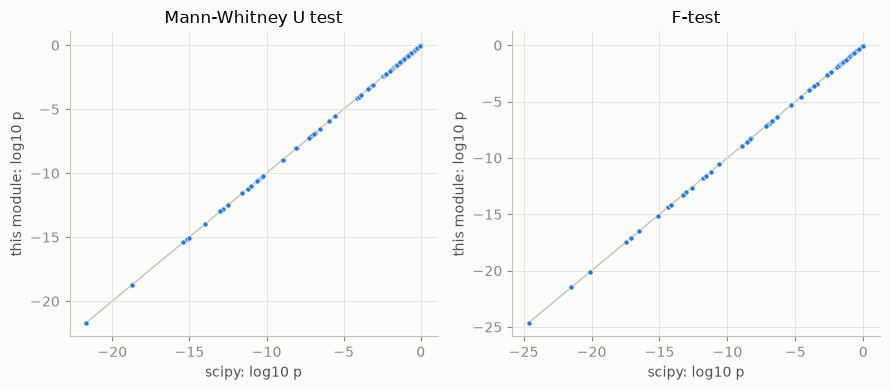

In [2]:
rng = np.random.default_rng(0)
n_per_class, n_features = 200, 500
y = np.repeat([0, 1], n_per_class)
shift = np.where(np.arange(n_features) < 50, rng.uniform(0, 1, n_features), 0)
X = rng.standard_normal((2 * n_per_class, n_features)) + np.outer(y, shift)

ours_u = log_mannwhitneyu(X, y)[0] / LOG10
ref_u = scipy_log10_u(X, y)
f_stat, _ = f_classif(X, y)
dfd = len(y) - 2
ours_f = log_f_sf(f_stat, 1, dfd) / LOG10
ref_f = scipy_log10_f(f_stat, 1, dfd)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, ours, ref, title in [(axes[0], ours_u, ref_u, 'Mann-Whitney U test'),
                             (axes[1], ours_f, ref_f, 'F-test')]:
    lo = min(ours.min(), ref.min())
    ax.plot([lo, 0], [lo, 0], color='#c3c2b7', linewidth=1, zorder=1)
    ax.scatter(ref, ours, s=14, color=OURS, edgecolor='#fcfcfb', linewidth=0.5, zorder=2)
    ax.set(title=title, xlabel='scipy: log10 p', ylabel='this module: log10 p')
fig.tight_layout()

print(f'largest difference, U test: {np.max(np.abs(ours_u - ref_u)):.1e} (log10 units)')
print(f'largest difference, F-test: {np.max(np.abs(ours_f - ref_f)):.1e} (log10 units)')

## 2. As the effect grows, scipy reaches 0

One feature per effect size: the second class is shifted by `delta`
standard deviations. 1,500 samples per class, about the size of a balanced
SCAN-B task. Every feature uses the same noise, so the curves are smooth.

The dashed line is the smallest float64 above 0. Where scipy's line stops,
its p-value is exactly 0.

The two tests behave differently:

- **F-test:** the p-value keeps shrinking as the effect grows. scipy hits 0
  near the middle of the range.
- **U test:** once the classes no longer overlap, every sample of one
  class ranks above every sample of the other, and U cannot grow further.
  Its p-value has a floor set by the class sizes. With 1,500 per class that
  floor is below the float64 limit, so scipy still reaches 0.

U test floor here: log10 p = -490
F-test at delta 6: log10 p = -1524


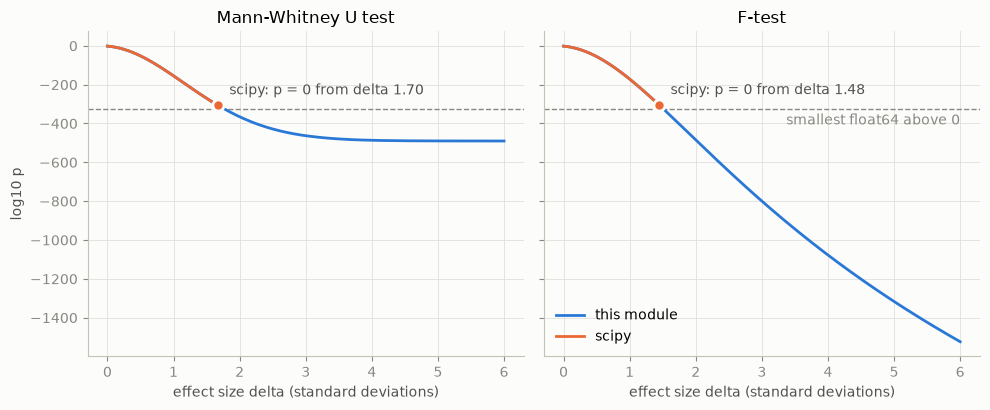

In [3]:
n_per_class = 1500
y = np.repeat([0, 1], n_per_class)
deltas = np.linspace(0, 6, 241)
noise = np.random.default_rng(1).standard_normal(2 * n_per_class)
X = noise[:, None] + np.outer(y, deltas)

ours_u = log_mannwhitneyu(X, y)[0] / LOG10
ref_u = scipy_log10_u(X, y)
f_stat, _ = f_classif(X, y)
dfd = len(y) - 2
ours_f = log_f_sf(f_stat, 1, dfd) / LOG10
ref_f = scipy_log10_f(f_stat, 1, dfd)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, ours, ref, title in [(axes[0], ours_u, ref_u, 'Mann-Whitney U test'),
                             (axes[1], ours_f, ref_f, 'F-test')]:
    ax.axhline(FLOAT_LIMIT, color='#898781', linewidth=1, linestyle='--')
    ax.plot(deltas, ours, color=OURS, label='this module')
    finite = np.isfinite(ref)
    ax.plot(deltas[finite], ref[finite], color=SCIPY, label='scipy')
    last = np.flatnonzero(finite)[-1]
    ax.plot(deltas[last], ref[last], 'o', color=SCIPY, markersize=8,
            markeredgecolor='#fcfcfb', markeredgewidth=2)
    ax.annotate(f'scipy: p = 0 from delta {deltas[last + 1]:.2f}',
                (deltas[last], ref[last]), xytext=(8, 8),
                textcoords='offset points', color='#52514e')
    ax.set(title=title, xlabel='effect size delta (standard deviations)')
axes[0].set_ylabel('log10 p')
axes[1].text(6, FLOAT_LIMIT - 25, 'smallest float64 above 0', color='#898781',
             ha='right', va='top')
axes[1].legend(loc='lower left')
fig.tight_layout()

print(f'U test floor here: log10 p = {ours_u.min():.0f}')
print(f'F-test at delta 6: log10 p = {ours_f[-1]:.0f}')

## 3. Why it matters: ranking many strong features

A selector keeps the k features with the smallest p-values. Here 2,000
features, 1,500 samples per class; 300 of them carry a signal, of evenly
spread strength from weak to very strong. The true order of strength is
known.

With scipy's p-values, every feature past the limit gets p = 0. They tie,
and the order among them is lost. The logs keep every feature distinct.
Orange dots are scipy's; where it has a value, it equals this module's and
covers the blue dot.

U test: scipy gives p = 0 to 170 features; distinct values among them here: 170
F-test: scipy gives p = 0 to 189 features; distinct values among them here: 189


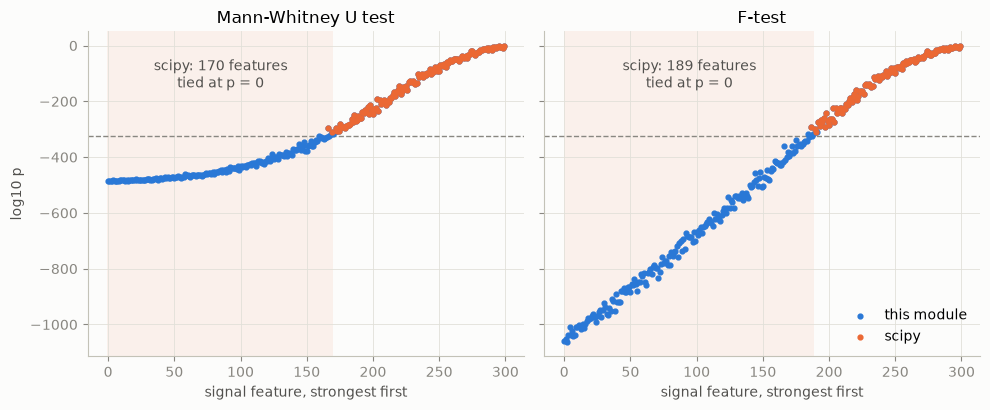

In [4]:
rng = np.random.default_rng(2)
n_features, n_signal = 2000, 300
strength = np.zeros(n_features)
strength[:n_signal] = np.linspace(4, 0.1, n_signal)   # feature 0 strongest
X = rng.standard_normal((2 * n_per_class, n_features)) + np.outer(y, strength)

ours_u = log_mannwhitneyu(X, y)[0] / LOG10
ref_u = scipy_log10_u(X, y)
f_stat, _ = f_classif(X, y)
ours_f = log_f_sf(f_stat, 1, dfd) / LOG10
ref_f = scipy_log10_f(f_stat, 1, dfd)

for name, ours, ref in [('U test', ours_u, ref_u), ('F-test', ours_f, ref_f)]:
    zeros = np.isinf(ref).sum()
    print(f'{name}: scipy gives p = 0 to {zeros} features; '
          f'distinct values among them here: {len(np.unique(ours[np.isinf(ref)]))}')

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
signal = np.arange(n_signal)
for ax, ours, ref, title in [(axes[0], ours_u, ref_u, 'Mann-Whitney U test'),
                             (axes[1], ours_f, ref_f, 'F-test')]:
    ax.axhline(FLOAT_LIMIT, color='#898781', linewidth=1, linestyle='--')
    # scipy on top: where it has a value it equals this module's, so blue
    # shows only where scipy has none.
    ax.scatter(signal, ours[:n_signal], s=12, color=OURS, label='this module', zorder=2)
    finite = np.isfinite(ref[:n_signal])
    ax.scatter(signal[finite], ref[:n_signal][finite], s=12, color=SCIPY,
               label='scipy', zorder=3)
    n_zero = (~finite).sum()
    if n_zero:
        ax.axvspan(-0.5, n_zero - 0.5, color='#eb6834', alpha=0.08, linewidth=0)
        ax.text(n_zero / 2, -150, f'scipy: {n_zero} features\ntied at p = 0',
                ha='center', color='#52514e')
    ax.set(title=title, xlabel='signal feature, strongest first')
axes[0].set_ylabel('log10 p')
axes[1].legend(loc='lower right')
fig.tight_layout()

## 4. Speed

Each function against scipy, on 3,000 samples (1,500 per class, about
SCAN-B's patient count) and a growing number of features. The data is
float32, as the runner holds it. Each time is the best of 3 runs.

- U test: `log_mannwhitneyu(X, y)` against `scipy.stats.mannwhitneyu(...,
  axis=0, method='asymptotic')`, both on all features at once.
- F-test: `log_f_sf(f, 1, dfd)` against `scipy.stats.f.logsf`, on the F
  statistics of the same data. Computing F itself (`f_classif`) is
  excluded: both would share it.

A tenth of the features carry a signal, so some p-values are tiny and the
F-test's slow path (the continued fraction) is exercised.

In [5]:
import timeit


def best_of(fn, *args, repeat=3, **kwargs):
    """Fastest of `repeat` single runs of fn(*args, **kwargs), in seconds."""
    return min(timeit.repeat(lambda: fn(*args, **kwargs), number=1, repeat=repeat))


n_per_class = 1500
y = np.repeat([0, 1], n_per_class)
dfd = len(y) - 2
feature_counts = [1000, 3000, 10000]
times = {key: [] for key in ('ours_u', 'scipy_u', 'ours_f', 'scipy_f')}

for n_features in feature_counts:
    rng = np.random.default_rng(3)
    strength = np.where(np.arange(n_features) < n_features // 10,
                        rng.uniform(0, 3, n_features), 0)
    X = (rng.standard_normal((len(y), n_features)) + np.outer(y, strength)).astype(np.float32)
    f_stat, _ = f_classif(X, y)
    a, b = X[y == 0], X[y == 1]

    times['ours_u'].append(best_of(log_mannwhitneyu, X, y))
    times['scipy_u'].append(best_of(mannwhitneyu, a, b, axis=0, method='asymptotic'))
    times['ours_f'].append(best_of(log_f_sf, f_stat, 1, dfd))
    times['scipy_f'].append(best_of(f_dist.logsf, f_stat, 1, dfd))

print(f"{'features':>9} {'U ours s':>9} {'U scipy s':>10} {'F ours ms':>10} {'F scipy ms':>11}")
for i, n_features in enumerate(feature_counts):
    print(f"{n_features:>9} {times['ours_u'][i]:>9.2f} {times['scipy_u'][i]:>10.2f} "
          f"{1e3 * times['ours_f'][i]:>10.1f} {1e3 * times['scipy_f'][i]:>11.1f}")

 features  U ours s  U scipy s  F ours ms  F scipy ms
     1000      0.21       0.37        3.8         1.1
     3000      0.65       1.17        6.6         2.7
    10000      2.15       3.76       10.2         4.1


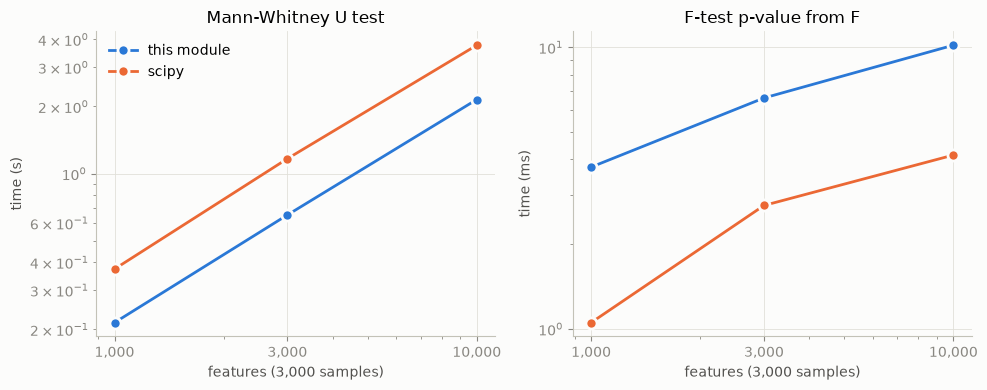

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, ours, ref, title, unit, scale in [
        (axes[0], 'ours_u', 'scipy_u', 'Mann-Whitney U test', 's', 1),
        (axes[1], 'ours_f', 'scipy_f', 'F-test p-value from F', 'ms', 1e3)]:
    ax.plot(feature_counts, scale * np.array(times[ours]), 'o-', color=OURS,
            markersize=8, markeredgecolor='#fcfcfb', markeredgewidth=2, label='this module')
    ax.plot(feature_counts, scale * np.array(times[ref]), 'o-', color=SCIPY,
            markersize=8, markeredgecolor='#fcfcfb', markeredgewidth=2, label='scipy')
    ax.set(title=title, xlabel='features (3,000 samples)', ylabel=f'time ({unit})',
           xscale='log', yscale='log')
    ax.set_xticks(feature_counts, [f'{n:,}' for n in feature_counts])
axes[0].legend(loc='upper left')
fig.tight_layout()

## 5. Accuracy against exact values

scipy is no reference below 1e-308, so the reference here is mpmath at 50
significant digits, which has no such limit. The error shown is relative:
|computed log p - exact log p| / |exact log p|. Float64 itself carries
about 1e-16. A point at the bottom edge means no error at all.

- **F-test:** exact p is the regularized incomplete beta, as in the
  module's test. 200 F values, from no signal to log10 p near -1500, for
  SCAN-B's size (dfd = 2,998) and BreastMNIST's (dfd = 778).
- **U test:** U, its tie correction and z are exact sums, so the only
  place for error is the tail of the normal distribution. The reference is
  log(erfc(z / sqrt 2)) in mpmath, for z from 0 to 60.

This measures the arithmetic. Whether the normal approximation is close to
the U test's exact permutation p-value far in the tail is a different
question, which no float format answers.

F-test, dfd = 2,998 (SCAN-B): largest error, this module 7.1e-12; scipy reaches p = 0 at log10 p = -320
F-test, dfd = 778 (BreastMNIST): largest error, this module 1.3e-13; scipy reaches p = 0 at log10 p = -312
U test tail: largest error, this module 4.7e-16


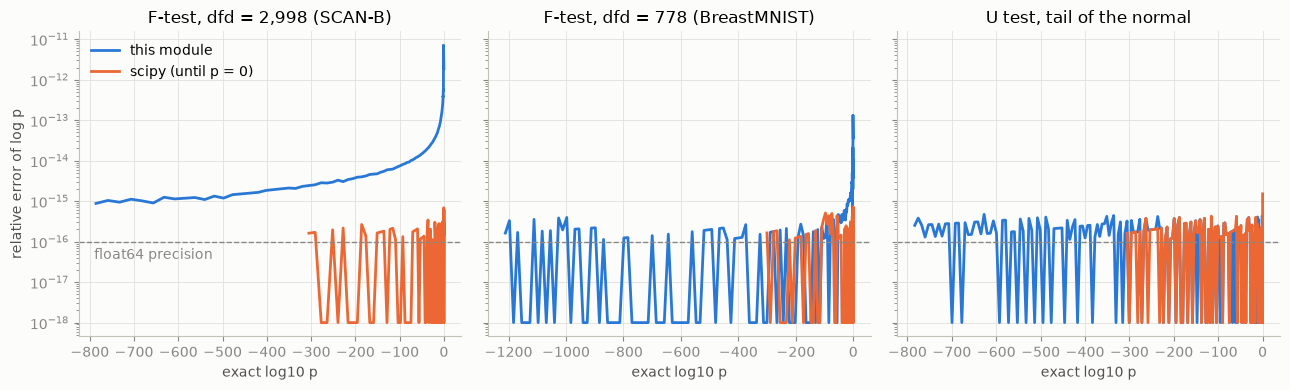

In [7]:
import mpmath
from scipy.stats import norm

mpmath.mp.dps = 50
EPS_FLOOR = 1e-18   # where a zero error is drawn


def exact_log_f_sf(f, dfn, dfd):
    x = mpmath.mpf(dfd) / (dfd + dfn * mpmath.mpf(f))
    return float(mpmath.log(mpmath.betainc(mpmath.mpf(dfd) / 2, mpmath.mpf(dfn) / 2,
                                           0, x, regularized=True)))


def rel_error(computed, exact):
    err = np.abs(computed - exact) / np.abs(exact)
    return np.maximum(err, EPS_FLOOR)


fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, dfd_case, label in [(axes[0], 2998, 'F-test, dfd = 2,998 (SCAN-B)'),
                            (axes[1], 778, 'F-test, dfd = 778 (BreastMNIST)')]:
    f_values = np.geomspace(0.05, 7000 if dfd_case == 2998 else 1e6, 200)
    exact = np.array([exact_log_f_sf(f, 1, dfd_case) for f in f_values])
    ours = log_f_sf(f_values, 1, dfd_case)
    with np.errstate(divide='ignore'):
        ref = f_dist.logsf(f_values, 1, dfd_case)
    finite = np.isfinite(ref)
    ax.plot(exact / LOG10, rel_error(ours, exact), color=OURS, label='this module')
    ax.plot(exact[finite] / LOG10, rel_error(ref[finite], exact[finite]), color=SCIPY,
            label='scipy (until p = 0)')
    ax.set(title=label, xlabel='exact log10 p', yscale='log')
    print(f'{label}: largest error, this module {rel_error(ours, exact).max():.1e}; '
          f'scipy reaches p = 0 at log10 p = {exact[~finite][0] / LOG10:.0f}')

z = np.linspace(0.01, 60, 200)
exact = np.array([float(mpmath.log(mpmath.erfc(mpmath.mpf(v) / mpmath.sqrt(2))))
                  for v in z])
ours = np.log(2) + norm.logsf(z)          # what log_mannwhitneyu computes from z
with np.errstate(divide='ignore'):
    ref = np.log(2 * norm.sf(z))          # scipy's p, then its log
finite = np.isfinite(ref)
axes[2].plot(exact / LOG10, rel_error(ours, exact), color=OURS, label='this module')
axes[2].plot(exact[finite] / LOG10, rel_error(ref[finite], exact[finite]), color=SCIPY,
             label='scipy (until p = 0)')
axes[2].set(title='U test, tail of the normal', xlabel='exact log10 p', yscale='log')
print(f'U test tail: largest error, this module {rel_error(ours, exact).max():.1e}')

axes[0].set_ylabel('relative error of log p')
axes[0].legend(loc='upper left')
for ax in axes:
    ax.axhline(1e-16, color='#898781', linewidth=1, linestyle='--')
axes[0].text(-790, 7e-17, 'float64 precision', color='#898781', va='top')
fig.tight_layout()